# 03 — Valence-related features: do they separate sad (Q3) from calm (Q4)?

`01_eda.ipynb` §8 showed that the 133 librosa features separate high from low arousal well (best ε² ≈ 0.51) but barely separate Q3 (sad) from Q4 (calm) (best ε² ≈ 0.03). Q3 and Q4 share low arousal and differ in valence. The music-emotion literature links valence mainly to harmony: major mode and consonant harmony to positive valence, minor mode and dissonant harmony to negative valence (Panda, Malheiro and Paiva, *Audio Features for Music Emotion Recognition: A Survey*, IEEE TAFFC 2023, Sec. 3.2).

`src/features_tonal.py` therefore extracts 22 harmony and tonality features listed in that survey: modality (major vs minor), key clarity, best major and minor key strength, the same modality and key clarity on 3-second segments, the 6-dimensional tonal centroid (tonnetz) and the harmonic change detection function.

This notebook checks, **on the training set of the official split only**, whether these features carry the information that was missing. Validation and test songs are not used, so nothing learned here can leak into the evaluation. Decision D13 in `docs/DECISIONS.md` refers to this notebook.

Figures and tables are saved to `results/valence/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
FEATURES = ROOT / "data" / "features"
SPLIT = ROOT / "data" / "raw" / "MERGE_Audio_Balanced" / "tvt_dataframes" / "tvt_70_15_15" / "tvt_70_15_15_train_audio_balanced.csv"
OUT = ROOT / "results" / "valence"
OUT.mkdir(parents=True, exist_ok=True)

QUADRANTS = ["Q1", "Q2", "Q3", "Q4"]
COLORS = {"Q1": "#E69F00", "Q2": "#D55E00", "Q3": "#0072B2", "Q4": "#009E73"}
NAMES = {"Q1": "Q1 happy", "Q2": "Q2 angry/tense", "Q3": "Q3 sad", "Q4": "Q4 calm"}
summary = {}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    plt.show()


tonal = pd.read_csv(FEATURES / "features_tonal.csv")
base = pd.read_csv(FEATURES / "features_librosa.csv")
train_ids = pd.read_csv(SPLIT)["Song"]
tonal_cols = [c for c in tonal.columns if c not in ["Song", "Quadrant"]]
base_cols = [c for c in base.columns if c not in ["Song", "Quadrant", "duration_loaded"]]
train = pd.DataFrame({"Song": train_ids}).merge(base, on="Song").merge(tonal.drop(columns="Quadrant"), on="Song").copy()
print(f"tonal features: {len(tonal_cols)}, librosa features: {len(base_cols)}, training songs: {len(train)}")

tonal features: 22, librosa features: 133, training songs: 2264


## 1. Data quality

**Purpose:** confirm that the new features are complete for all 3,232 songs and usable (no missing, infinite or constant values) before analysing them.

In [2]:
checks = {
    "songs with tonal features": len(tonal),
    "missing values": int(tonal[tonal_cols].isna().sum().sum()),
    "infinite values": int(np.isinf(tonal[tonal_cols].to_numpy()).sum()),
    "constant features": int((tonal[tonal_cols].std() == 0).sum()),
    "songs in features_librosa.csv not in features_tonal.csv": len(set(base["Song"]) - set(tonal["Song"])),
}
display(pd.Series(checks).to_frame("value"))
desc = train[tonal_cols].describe().T
desc.to_csv(OUT / "01_tonal_description_train.csv")
display(desc.round(3))
summary["quality"] = checks

,value
songs with tonal features,3232
missing values,0
infinite values,0
constant features,0
songs in features_librosa.csv not in features_tonal.csv,0


,count,mean,std,min,25%,50%,75%,max
key_clarity,2264.0,0.682,0.168,0.221,0.565,0.714,0.816,0.976
modality,2264.0,0.051,0.173,-0.397,-0.081,0.048,0.188,0.437
key_strength_major,2264.0,0.633,0.194,0.111,0.486,0.654,0.794,0.975
key_strength_minor,2264.0,0.582,0.137,0.199,0.492,0.585,0.677,0.976
key_clarity_segments_mean,2264.0,0.637,0.119,0.279,0.555,0.651,0.730,0.890
key_clarity_segments_std,2264.0,0.094,0.033,0.007,0.069,0.093,0.116,0.211
modality_segments_mean,2264.0,0.024,0.093,-0.324,-0.042,0.024,0.087,0.334
modality_segments_std,2264.0,0.114,0.041,0.009,0.084,0.112,0.141,0.283
tonnetz_01_mean,2264.0,0.042,0.130,-0.524,-0.031,0.040,0.119,0.524
tonnetz_01_std,2264.0,0.121,0.053,0.029,0.082,0.113,0.151,0.484


**Findings.** All 3,232 songs have the 22 tonal features, with no missing, infinite or constant values, and the same songs as the librosa features.

## 2. Modality and key clarity per quadrant

**Purpose:** check the direction predicted by the literature. Modality is the difference between the best major and the best minor key correlation: positive means the excerpt fits a major key better, negative a minor key. If the hypothesis holds, Q4 (calm, positive valence) should be more major than Q3 (sad, negative valence).

,modality,modality_segments_mean,key_clarity,key_strength_major
Quadrant,,,,
Q1,0.057,0.031,0.669,0.624
Q2,-0.027,-0.016,0.567,0.497
Q3,0.066,0.028,0.734,0.686
Q4,0.108,0.052,0.759,0.725


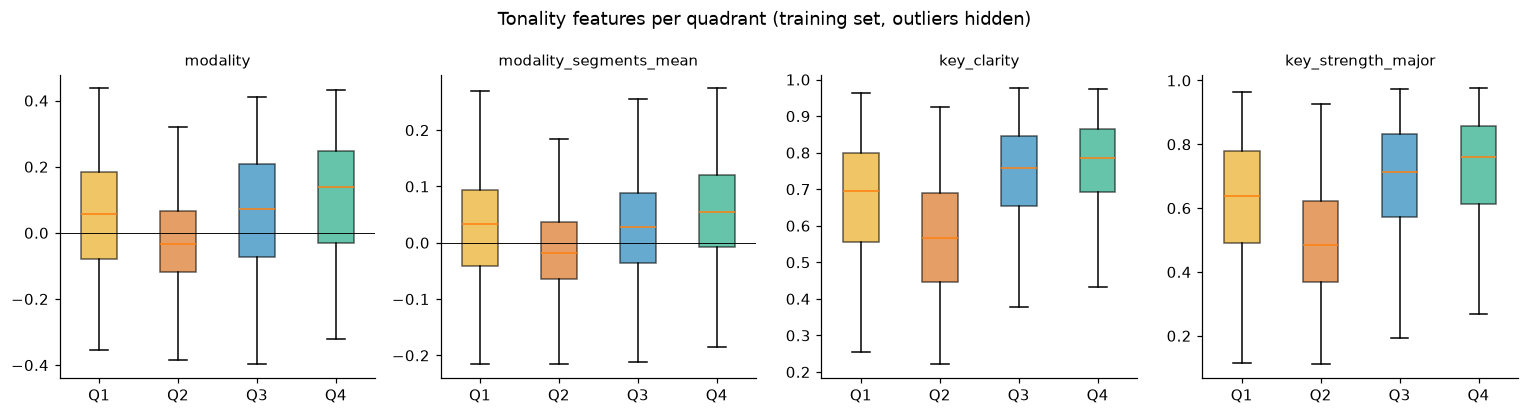

In [3]:
show = ["modality", "modality_segments_mean", "key_clarity", "key_strength_major"]
means = train.groupby("Quadrant")[show].mean().reindex(QUADRANTS)
means.round(4).to_csv(OUT / "02_means_by_quadrant.csv")
display(means.round(3))

fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, col in zip(axes, show):
    parts = [train.loc[train["Quadrant"] == q, col] for q in QUADRANTS]
    bp = ax.boxplot(parts, tick_labels=QUADRANTS, showfliers=False, patch_artist=True)
    for patch, q in zip(bp["boxes"], QUADRANTS):
        patch.set_facecolor(COLORS[q])
        patch.set_alpha(0.6)
    ax.axhline(0, color="black", lw=0.6) if col.startswith("modality") else None
    ax.set_title(col, fontsize=10)
fig.suptitle("Tonality features per quadrant (training set, outliers hidden)")
save(fig, "02_tonality_boxplots")
summary["modality_mean_by_quadrant"] = means["modality"].round(4).to_dict()

**Findings.** The direction matches the literature: Q4 (calm) has the most major modality on average (about +0.11), Q3 (sad) less (about +0.07), and Q2 (angry/tense) is the only quadrant with a negative, minor-leaning mean. Key clarity is higher in the low-arousal quadrants. The distributions of Q3 and Q4 overlap strongly, so the difference is small.

## 3. Q3 vs Q4: new features against the existing ones

**Purpose:** the central question. For every feature, the Kruskal–Wallis test (as in `01_eda.ipynb` §8) measures how differently it is distributed in Q3 and Q4; ε² ranges from 0 (no difference) to 1. The best new features are compared with the best of the 133 existing ones.

,feature,epsilon2,p,group
0,mfcc_03_std,0.0250,0.0000,librosa (existing)
1,mfcc_03_mean,0.0237,0.0000,librosa (existing)
2,modality_segments_mean,0.0195,0.0000,tonal (new)
3,mfcc_13_std,0.0185,0.0000,librosa (existing)
4,spectral_contrast_03_mean,0.0163,0.0000,librosa (existing)
5,mfcc_12_std,0.0161,0.0000,librosa (existing)
6,mfcc_18_std,0.0149,0.0000,librosa (existing)
7,spectral_contrast_04_mean,0.0140,0.0000,librosa (existing)
8,mfcc_delta_03_std,0.0136,0.0001,librosa (existing)
9,modality,0.0133,0.0001,tonal (new)


best new feature: modality_segments_mean (ε² = 0.0195)
best existing feature: mfcc_03_std (ε² = 0.0250)
new features with p < 0.01: 5 of 22


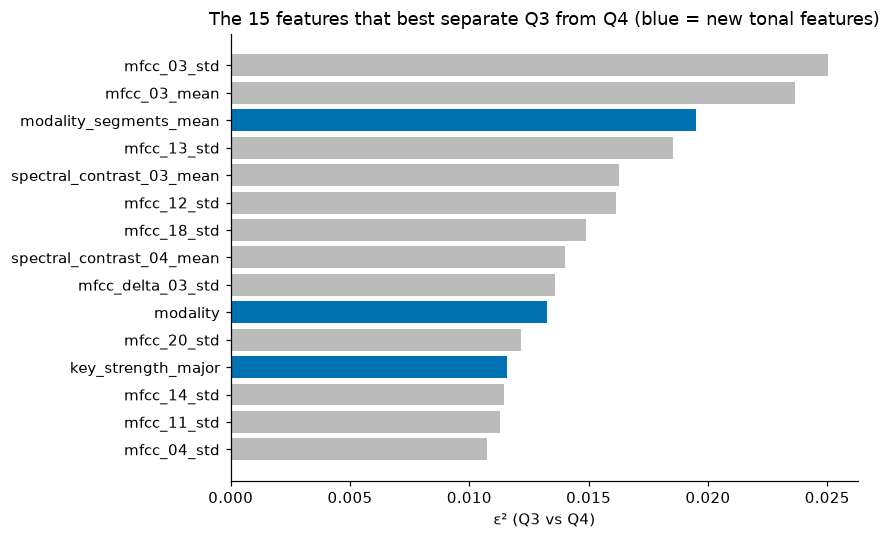

In [4]:
def kruskal_eps(frame, cols, labels):
    n, k = len(frame), labels.nunique()
    rows = []
    for col in cols:
        h, p = stats.kruskal(*[g[col].to_numpy() for _, g in frame.groupby(labels)])
        rows.append({"feature": col, "epsilon2": (h - k + 1) / (n - k), "p": p})
    return pd.DataFrame(rows).sort_values("epsilon2", ascending=False).reset_index(drop=True)


low = train[train["Quadrant"].isin(["Q3", "Q4"])]
q34_tonal = kruskal_eps(low, tonal_cols, low["Quadrant"]).assign(group="tonal (new)")
q34_base = kruskal_eps(low, base_cols, low["Quadrant"]).assign(group="librosa (existing)")
q34 = pd.concat([q34_tonal, q34_base]).sort_values("epsilon2", ascending=False).reset_index(drop=True)
q34.to_csv(OUT / "03_q3_vs_q4_ranking.csv", index=False)
display(q34.head(15).round(4))
print(f"best new feature: {q34_tonal.iloc[0]['feature']} (ε² = {q34_tonal.iloc[0]['epsilon2']:.4f})")
print(f"best existing feature: {q34_base.iloc[0]['feature']} (ε² = {q34_base.iloc[0]['epsilon2']:.4f})")
print(f"new features with p < 0.01: {(q34_tonal['p'] < 0.01).sum()} of {len(q34_tonal)}")

top = q34.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top["feature"], top["epsilon2"], color=np.where(top["group"] == "tonal (new)", "#0072B2", "#BBBBBB"))
ax.set_xlabel("ε² (Q3 vs Q4)")
ax.set_title("The 15 features that best separate Q3 from Q4 (blue = new tonal features)")
save(fig, "03_q3_vs_q4_top_features")
summary["q3_q4_best_new"] = {"feature": q34_tonal.iloc[0]["feature"], "epsilon2": round(float(q34_tonal.iloc[0]["epsilon2"]), 4)}
summary["q3_q4_best_existing"] = {"feature": q34_base.iloc[0]["feature"], "epsilon2": round(float(q34_base.iloc[0]["epsilon2"]), 4)}

**Findings.** On their own, the new features do not separate Q3 from Q4 better than the existing ones: the best new feature, modality measured on 3-second segments (ε² ≈ 0.020), stays below the best existing one, the standard deviation of the third MFCC (ε² ≈ 0.025). Several new features still differ significantly between the two quadrants (modality, major key strength, key clarity), so the information is present but weak.

## 4. Q1 vs Q2: valence at high arousal

**Purpose:** valence also separates Q1 (happy) from Q2 (angry/tense). The same comparison checks whether the tonal features help there.

In [5]:
high = train[train["Quadrant"].isin(["Q1", "Q2"])]
q12_tonal = kruskal_eps(high, tonal_cols, high["Quadrant"])
q12_base = kruskal_eps(high, base_cols, high["Quadrant"])
q12_tonal.to_csv(OUT / "04_q1_vs_q2_ranking_tonal.csv", index=False)
comparison = pd.DataFrame({
    "best new feature": q12_tonal.head(5)["feature"].values,
    "ε² (new)": q12_tonal.head(5)["epsilon2"].round(3).values,
    "best existing feature": q12_base.head(5)["feature"].values,
    "ε² (existing)": q12_base.head(5)["epsilon2"].round(3).values,
})
comparison.to_csv(OUT / "04_q1_vs_q2_comparison.csv", index=False)
display(comparison)
summary["q1_q2_best_new"] = {"feature": q12_tonal.iloc[0]["feature"], "epsilon2": round(float(q12_tonal.iloc[0]["epsilon2"]), 4)}
summary["q1_q2_best_existing"] = {"feature": q12_base.iloc[0]["feature"], "epsilon2": round(float(q12_base.iloc[0]["epsilon2"]), 4)}

,best new feature,ε² (new),best existing feature,ε² (existing)
0,tonnetz_03_std,0.218,spectral_contrast_04_mean,0.397
1,tonnetz_06_std,0.204,spectral_contrast_05_mean,0.391
2,harmonic_change_mean,0.184,spectral_contrast_03_mean,0.371
3,tonnetz_05_std,0.180,spectral_contrast_05_std,0.349
4,tonnetz_04_std,0.169,chroma_04_mean,0.287


**Findings.** At high arousal the tonal features are informative: the variation of the tonal centroid (tonnetz) and the amount of harmonic change separate happy from angry/tense music (ε² about 0.2), in line with the survey's link between consonant, stable harmony and positive valence. The existing features separate Q1 from Q2 even better (spectral contrast, ε² about 0.4), so for this pair the tonal features mostly confirm information that is already present.

## 5. Is the information new?

**Purpose:** a weak feature can still help a model if it carries information the other features do not. For each new feature, the strongest absolute Spearman correlation with any of the 133 existing features is computed on the training set. A low value means the feature measures something the existing set does not.

,feature,max |ρ| with existing,most correlated existing feature
16,tonnetz_05_mean,0.146,chroma_05_std
5,key_clarity_segments_std,0.156,chroma_06_std
18,tonnetz_06_mean,0.205,chroma_10_mean
6,modality_segments_mean,0.255,spectral_contrast_04_mean
7,modality_segments_std,0.260,spectral_contrast_03_mean
1,modality,0.281,spectral_contrast_03_mean
14,tonnetz_04_mean,0.291,chroma_03_std
12,tonnetz_03_mean,0.299,chroma_08_std
3,key_strength_minor,0.308,spectral_contrast_03_mean
4,key_clarity_segments_mean,0.450,spectral_contrast_03_mean


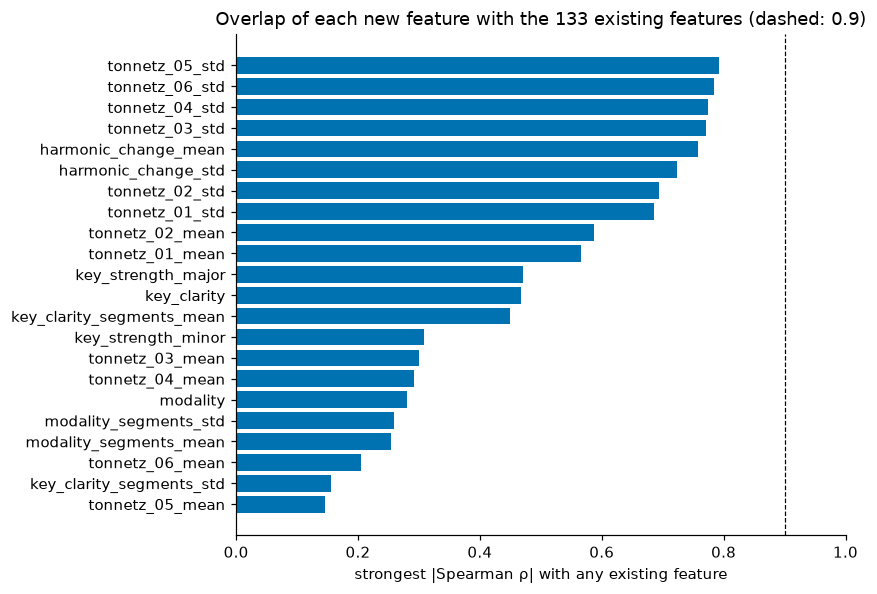

In [6]:
corr = pd.DataFrame({
    "feature": tonal_cols,
    "max |ρ| with existing": [train[base_cols].corrwith(train[c], method="spearman").abs().max() for c in tonal_cols],
    "most correlated existing feature": [train[base_cols].corrwith(train[c], method="spearman").abs().idxmax() for c in tonal_cols],
}).sort_values("max |ρ| with existing")
corr.round(3).to_csv(OUT / "05_redundancy_with_existing.csv", index=False)
display(corr.round(3))

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(corr["feature"], corr["max |ρ| with existing"], color="#0072B2")
ax.axvline(0.9, color="black", lw=0.8, ls="--")
ax.set_xlabel("strongest |Spearman ρ| with any existing feature")
ax.set_xlim(0, 1)
ax.set_title("Overlap of each new feature with the 133 existing features (dashed: 0.9)")
save(fig, "05_redundancy_with_existing")
summary["modality_max_corr_existing"] = round(float(corr.set_index("feature").loc["modality", "max |ρ| with existing"]), 3)
summary["new_features_corr_over_0.9"] = int((corr["max |ρ| with existing"] > 0.9).sum())

**Findings.** No new feature duplicates an existing one (none above |ρ| = 0.9). The modality features are only weakly related to any existing feature (strongest |ρ| below 0.3), so they add information the librosa set did not contain. Key clarity and key strength overlap moderately with spectral contrast (about 0.47), and the tonnetz variation and harmonic change features overlap more (0.7–0.8), mostly with chroma.

## 6. Conclusion and decision

The tonal features point in the direction the literature predicts and add new information, but on their own they do not solve the confusion between sad and calm music, and for happy vs angry/tense they are informative but weaker than the existing features. The modality features are the ones that add genuinely new information. Whether they help a classifier can be decided only by training with and without them, on the same splits.

**Decision supported:** D13 — every classical model is trained twice, with the 133 librosa features and with the 133 + 22 tonal features, under both protocols; the effect is judged on macro-F1 and on the number of Q3/Q4 confusions in the test confusion matrix. The new features are kept as a block: none is selected or removed on the basis of these results.

All numbers are written to `results/valence/summary.json`.

In [7]:
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float), encoding="utf-8")
print(json.dumps(summary, indent=2, default=float))

{
  "quality": {
    "songs with tonal features": 3232,
    "missing values": 0,
    "infinite values": 0,
    "constant features": 0,
    "songs in features_librosa.csv not in features_tonal.csv": 0
  },
  "modality_mean_by_quadrant": {
    "Q1": 0.0572,
    "Q2": -0.0272,
    "Q3": 0.0658,
    "Q4": 0.1077
  },
  "q3_q4_best_new": {
    "feature": "modality_segments_mean",
    "epsilon2": 0.0195
  },
  "q3_q4_best_existing": {
    "feature": "mfcc_03_std",
    "epsilon2": 0.025
  },
  "q1_q2_best_new": {
    "feature": "tonnetz_03_std",
    "epsilon2": 0.2178
  },
  "q1_q2_best_existing": {
    "feature": "spectral_contrast_04_mean",
    "epsilon2": 0.3966
  },
  "modality_max_corr_existing": 0.281,
  "new_features_corr_over_0.9": 0
}
